<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


<Axes: >

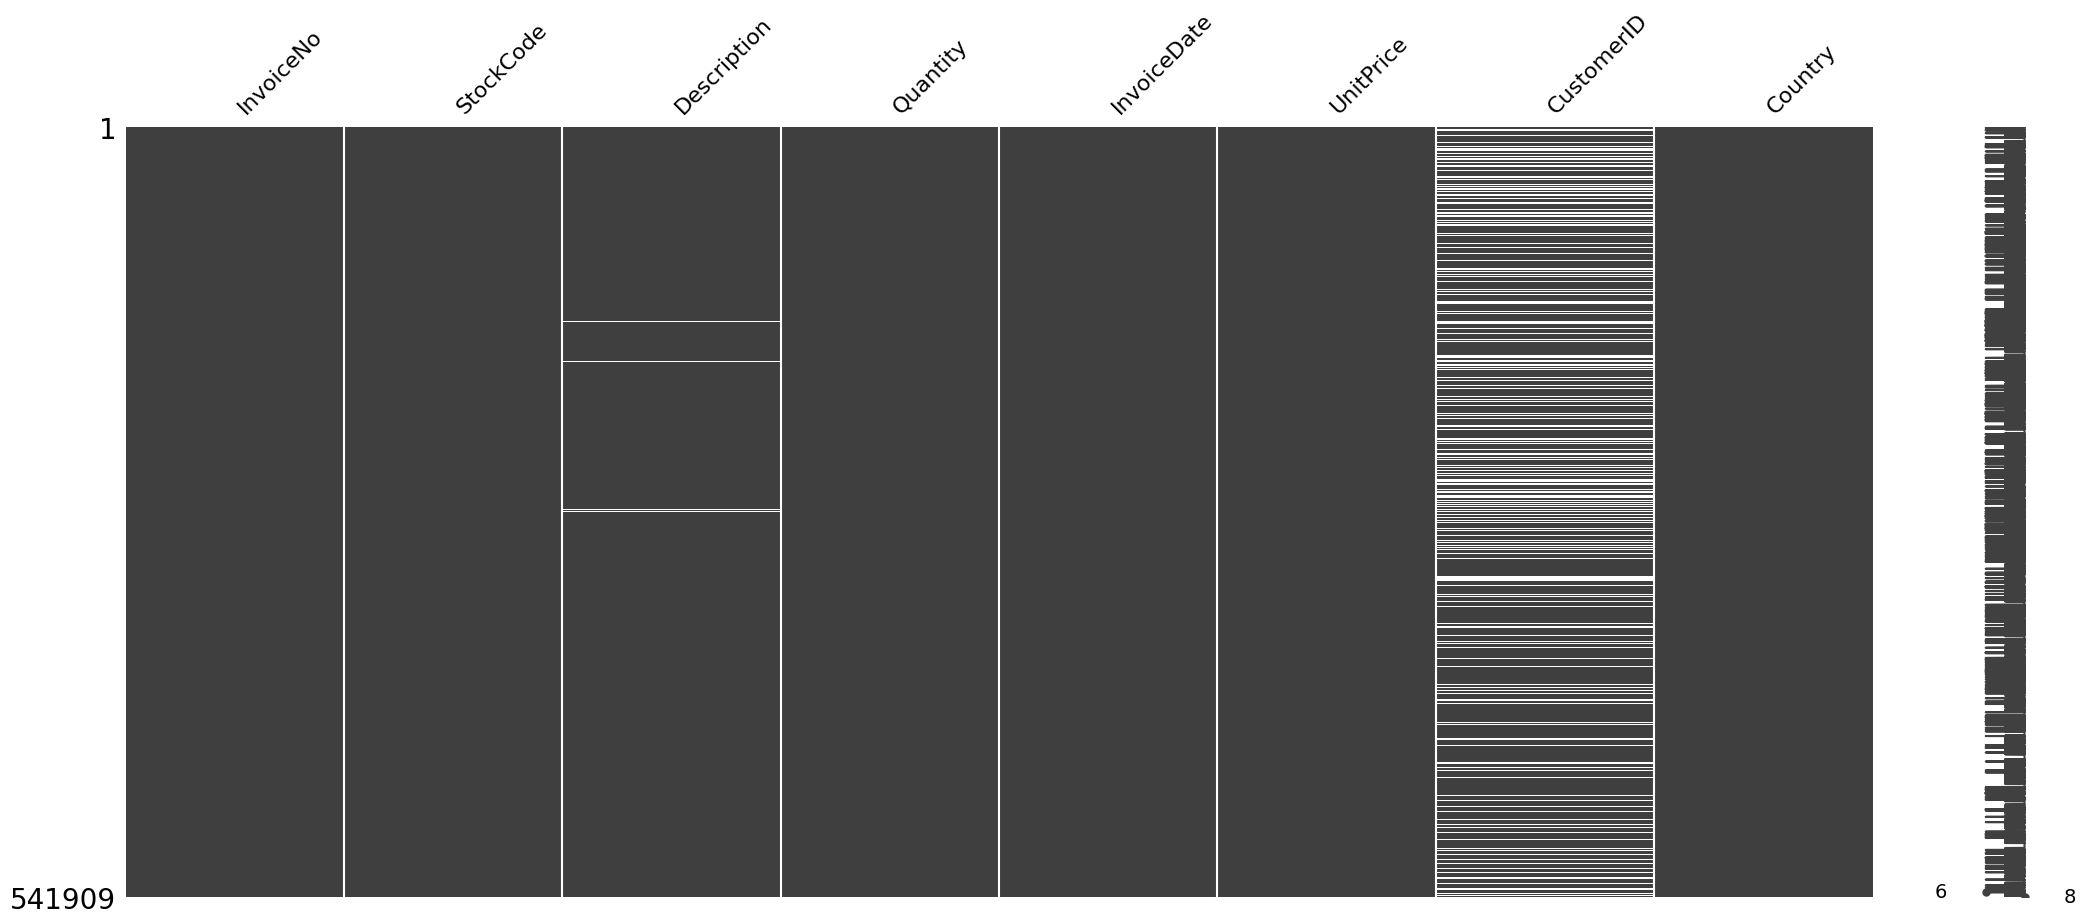

In [ ]:
import math
import numpy as np
import pandas
import pandas as pd
import missingno as ms
from google.colab import files

#Load dataset
dataset= pd.read_excel('/OnlineRetail.xlsx')
dataset.head(5)
#Conceptualizing the dataset
copy=dataset
dataset.shape
dataset.info()
#Now, find missing values and note them
ms.matrix(dataset)

<class 'pandas.core.frame.DataFrame'>
Index: 406829 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    406829 non-null  object        
 1   StockCode    406829 non-null  object        
 2   Description  406829 non-null  object        
 3   Quantity     406829 non-null  int64         
 4   InvoiceDate  406829 non-null  datetime64[ns]
 5   UnitPrice    406829 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      406829 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 27.9+ MB


<Axes: >

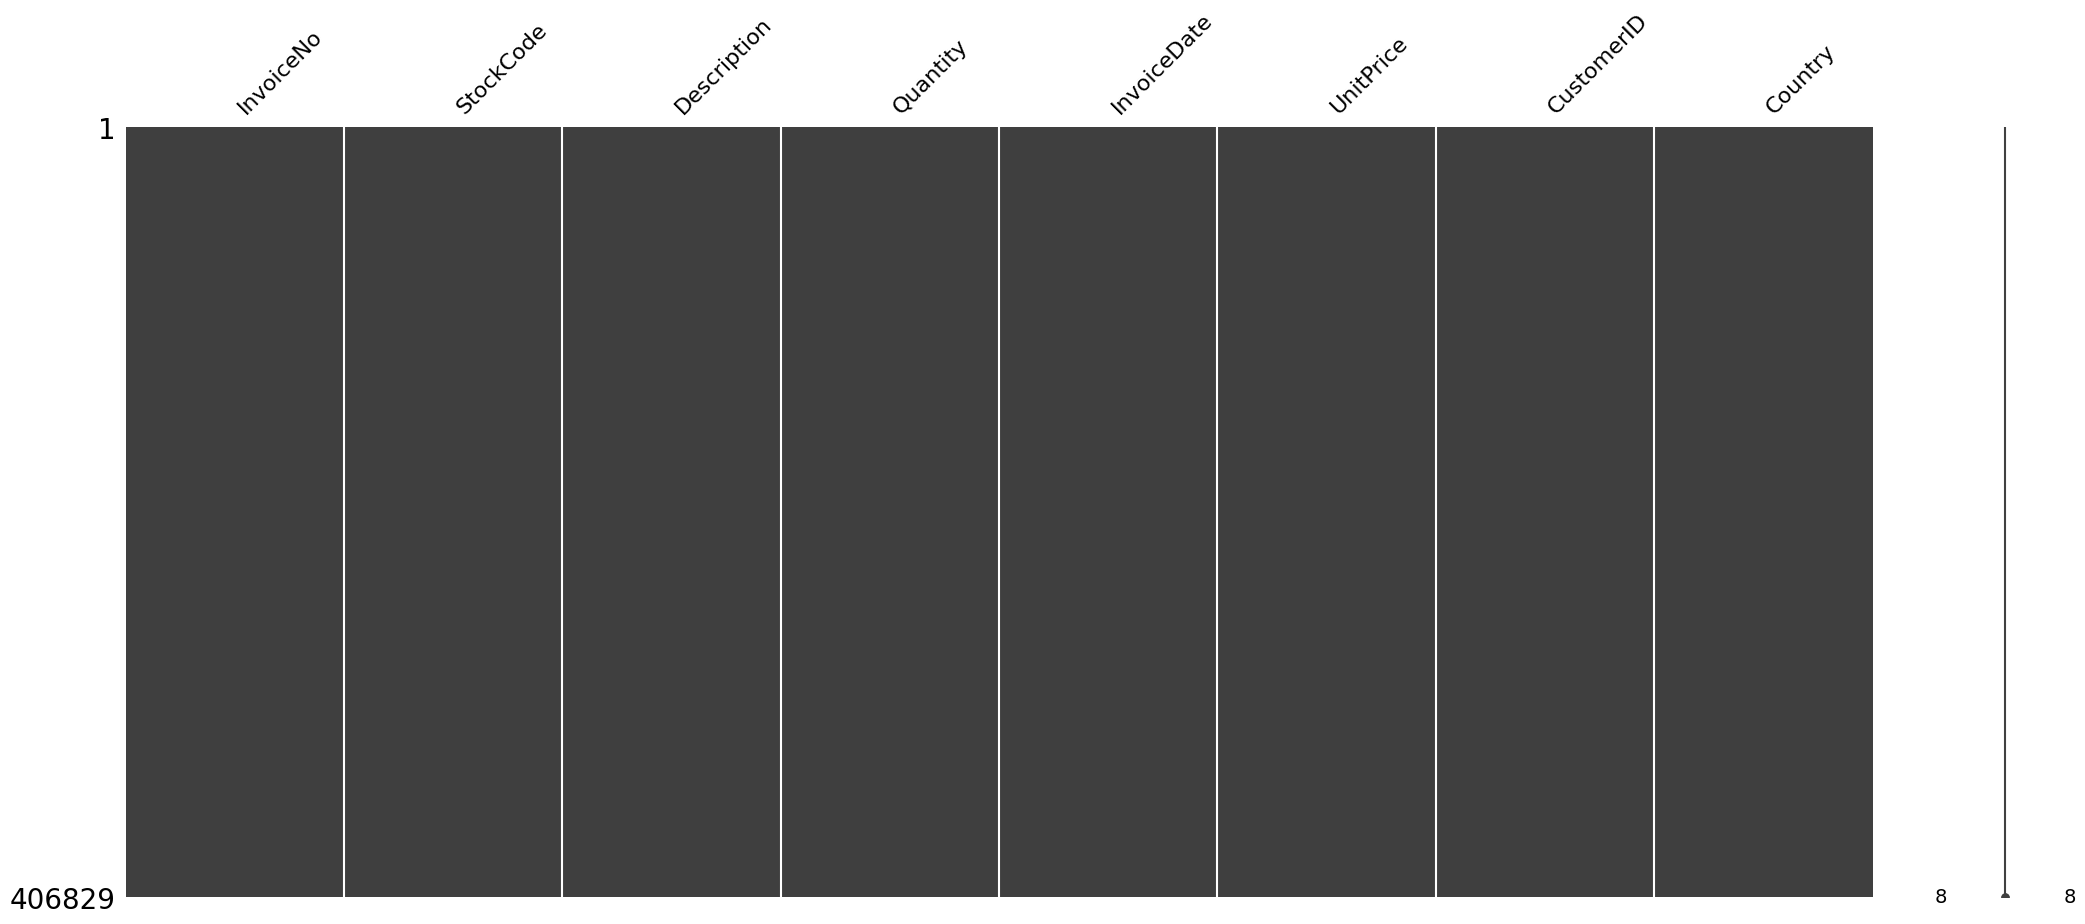

In [ ]:
#Most missing data in Customer ID, clean it out
dataset=dataset.loc[pd.isnull(dataset.CustomerID)==False]
dataset.info()
ms.matrix(dataset) #Sanity check to make sure its all out

In [ ]:
dataset.describe(include='all') #Summarize


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,397924.0,397924,397924,397924.000000,397924,397924.000000,397924.000000,397924
unique,18536.0,3665,3877,NaN,NaN,NaN,NaN,37
top,576339.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,542.0,2035,2028,NaN,NaN,NaN,NaN,354345
mean,NaN,NaN,NaN,13.021823,2011-07-10 23:43:36.912475648,3.116174,15294.315171,NaN
min,NaN,NaN,NaN,1.000000,2010-12-01 08:26:00,0.000000,12346.000000,NaN
25%,NaN,NaN,NaN,2.000000,2011-04-07 11:12:00,1.250000,13969.000000,NaN
50%,NaN,NaN,NaN,6.000000,2011-07-31 14:39:00,1.950000,15159.000000,NaN
75%,NaN,NaN,NaN,12.000000,2011-10-20 14:33:00,3.750000,16795.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,8142.750000,18287.000000,NaN


In [ ]:
#In excel i noticed cancelled orders, and some missing ID's-- check for those and also remove them
dataset=dataset[dataset['Quantity']>0]
dataset.dropna(subset=['CustomerID'],how='all',inplace=True) #Only remove completely blank rows of customer ID and update the data inplace
dataset.to_excel('OnlineRetailCleaned.xlsx',index=False)
files.download()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
dataset.shape

(397924, 8)

In [ ]:
#Now to do some aggregated fields
import matplotlib.pyplot as plt
import datetime as dt

In [ ]:
#Performing RFM -- first Create a new column that contains ONLY the date of the invoice
dataset['Date']=pd.to_datetime(dataset['InvoiceDate']).dt.date
dataset.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Date
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12-01
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12-01
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01


In [ ]:
#doing recentcy table, first group all the customers by ID, then find the last purchase date for each customer, then calculate how long its been since that purchase
dataset_recent=dataset.groupby('CustomerID',as_index=False)['Date'].max()
dataset_recent.columns=['CustomerID','LastPurchaseDate']
recent_date=dataset_recent['LastPurchaseDate'].max()
dataset_recent['Recency']=dataset_recent['LastPurchaseDate'].apply(lambda x:(recent_date-x).days)
dataset_recent.head()

,CustomerID,LastPurchaseDate,Recency
0,12346.0,2011-01-18,325
1,12347.0,2011-12-07,2
2,12348.0,2011-09-25,75
3,12349.0,2011-11-21,18
4,12350.0,2011-02-02,310


In [ ]:
#now doing frequency, look at unique purchases per customer, then calculate the number of purchases each one had made
copy= dataset
copy.drop_duplicates(subset=['InvoiceNo','CustomerID'], keep='first',inplace=True)
dataset_frequency=copy.groupby('CustomerID', as_index=False)['InvoiceNo'].count()
dataset_frequency.columns=['CustomerID','Frequency']
dataset_frequency.head()

,CustomerID,Frequency
0,12346.0,1
1,12347.0,7
2,12348.0,4
3,12349.0,1
4,12350.0,1


In [ ]:
# Now we do Monetary amount
dataset['TotalCost']=dataset['Quantity']*dataset['UnitPrice']
dataset_monetary=dataset.groupby(['CustomerID'],as_index= False)['TotalCost'].sum()
dataset_monetary.columns=['CustomerID','Monetary']
dataset_monetary.head()

,CustomerID,Monetary
0,12346.0,77183.60
1,12347.0,163.16
2,12348.0,331.36
3,12349.0,15.00
4,12350.0,25.20


In [ ]:
#Now to create the table, drop the date column and set the CustomerID as the index
rfm_dataset=dataset_recent.merge(dataset_frequency.merge(dataset_monetary,on='CustomerID'),on='CustomerID')
rfm_dataset.set_index('CustomerID',inplace=True)
rfm_dataset.drop('LastPurchaseDate',axis=1,inplace=True)
rfm_dataset.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,325,1,77183.60
12347.0,2,7,163.16
12348.0,75,4,331.36
12349.0,18,1,15.00
12350.0,310,1,25.20


In [ ]:
#ranking customers by Monetary rank
customer_rank=rfm_dataset
customer_rank['Rank']=customer_rank['Monetary'].rank(ascending=True)
customer_rank.sort_values('Rank',ascending=True)
#customer_rank.head()

,Recency,Frequency,Monetary,Rank
CustomerID,,,,
13256.0,14,1,0.00,1.0
13271.0,37,1,0.39,2.5
17914.0,3,1,0.39,2.5
15503.0,362,1,0.42,4.5
15645.0,18,1,0.42,4.5
...,...,...,...,...
17949.0,1,45,29999.69,4335.0
15098.0,182,3,39916.50,4336.0
18102.0,0,60,42053.60,4337.0
